# Sequence to sequence: the bottleneck and how attention removes it

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wnukmat/robot-learning-notebooks/blob/main/notebooks/1_foundations/05_sequence_to_sequence.ipynb) &nbsp; Guide note: [guide-sequence-to-sequence](https://www.matthewwnuk.com/guide-sequence-to-sequence.html#run)

Three models learn the same task: read a sequence of symbols and write it reversed.

1. an encoder and decoder joined by a single vector,
2. the same pair with attention, so the decoder can look back at every input position,
3. a small transformer.

The first fails as inputs get longer. The other two do not. By default the notebook loads trained
weights from the Hugging Face Hub so that it runs in seconds. Set `TRAIN = True` to train them yourself,
which takes a few minutes on a GPU.

In [1]:
# Setup. On Colab this installs the small helper package; where it is already installed it does nothing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("guide_utils") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/wnukmat/robot-learning-notebooks"])

In [2]:
import os, numpy as np, torch, torch.nn as nn, torch.nn.functional as F, matplotlib.pyplot as plt
from guide_utils import data, style
style.use(); dev = "cuda" if torch.cuda.is_available() else "cpu"
TRAIN = False
V, PAD, BOS, EOS = 20, 20, 21, 22; NV = 23; LMAX = 30; H = 96            # 20 symbols, plus padding, start and end tokens

def batch(n, L=None, lo=3, hi=LMAX, g=None):
    """Random sequences and their reversals. tgt is [BOS, reversed..., EOS]."""
    Ls = torch.full((n,), L) if L else torch.randint(lo, hi + 1, (n,), generator=g); m = int(Ls.max())
    src = torch.full((n, m), PAD); tgt = torch.full((n, m + 2), PAD)
    for i, l in enumerate(Ls.tolist()):
        s = torch.randint(0, V, (l,), generator=g); src[i, :l] = s; tgt[i, 0] = BOS; tgt[i, 1:l + 1] = s.flip(0); tgt[i, l + 1] = EOS
    return src.to(dev), tgt.to(dev)

src, tgt = batch(1, L=8); print("input ", src[0].tolist()); print("target", tgt[0].tolist())

input  [0, 7, 17, 6, 10, 6, 17, 0]
target [21, 0, 17, 6, 10, 6, 17, 7, 0, 22]


## The models

`RNN(attn=False)` passes only the encoder's final state to the decoder: the whole input has to fit in
96 numbers. `RNN(attn=True)` keeps every encoder output and, at each step, takes a weighted average of
them, with weights from a softmax over dot products.

In [3]:
class RNN(nn.Module):
    def __init__(self, attn):
        super().__init__(); self.attn = attn; self.emb = nn.Embedding(NV, H, padding_idx=PAD); self.enc = nn.GRU(H, H, batch_first=True)
        self.dec = nn.GRU(H + (H if attn else 0), H, batch_first=True); self.out = nn.Linear(H * (2 if attn else 1), NV); self.q = nn.Linear(H, H)
    def forward(self, src, tin, want_weights=False):
        mask = src != PAD; lens = mask.sum(1); enc_out, _ = self.enc(self.emb(src)); h = enc_out[torch.arange(len(src)), lens - 1][None].contiguous()
        if not self.attn:
            dec_out, _ = self.dec(self.emb(tin), h); return self.out(dec_out)                  # the single vector h is all the decoder gets
        outs, ws = [], []; ctx = torch.zeros(len(src), H, device=src.device)
        for t in range(tin.shape[1]):
            d, h = self.dec(torch.cat([self.emb(tin[:, t]), ctx], -1)[:, None], h)
            score = (enc_out @ self.q(d[:, 0])[:, :, None])[:, :, 0].masked_fill(~mask, -1e9); w = score.softmax(-1)
            ctx = (w[:, :, None] * enc_out).sum(1); outs.append(self.out(torch.cat([d[:, 0], ctx], -1))); ws.append(w)
        o = torch.stack(outs, 1); return (o, torch.stack(ws, 1)) if want_weights else o

class Transformer(nn.Module):
    def __init__(self):
        super().__init__(); self.emb = nn.Embedding(NV, H, padding_idx=PAD); self.pos = nn.Embedding(LMAX + 4, H)
        self.t = nn.Transformer(H, 4, 2, 2, 4 * H, 0.0, batch_first=True, norm_first=True); self.out = nn.Linear(H, NV)
    def e(self, x): return self.emb(x) + self.pos(torch.arange(x.shape[1], device=x.device))[None]
    def forward(self, src, tin):
        causal = nn.Transformer.generate_square_subsequent_mask(tin.shape[1], device=src.device)
        return self.out(self.t(self.e(src), self.e(tin), tgt_mask=causal, src_key_padding_mask=src == PAD, tgt_key_padding_mask=tin == PAD, memory_key_padding_mask=src == PAD))

## Training with teacher forcing

The decoder is given the correct earlier tokens (`tgt[:, :-1]`) and trained to predict the next one at
every position at once (`tgt[:, 1:]`).

In [4]:
def train(m, steps=4000):
    opt = torch.optim.AdamW(m.parameters(), 2e-3); sched = torch.optim.lr_scheduler.OneCycleLR(opt, 2e-3, total_steps=steps, pct_start=0.1)
    for it in range(steps):
        src, tgt = batch(128); loss = F.cross_entropy(m(src, tgt[:, :-1]).reshape(-1, NV), tgt[:, 1:].reshape(-1), ignore_index=PAD)
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step(); sched.step()
    return m

models = {}
for name, make in (("bottleneck", lambda: RNN(False)), ("attention", lambda: RNN(True)), ("transformer", Transformer)):
    torch.manual_seed(0); m = make().to(dev)
    if TRAIN:
        train(m)
        if os.environ.get("GUIDE_SAVE"): torch.save(m.state_dict(), os.path.join(os.environ["GUIDE_SAVE"], f"{name}.pt"))
    else:
        m.load_state_dict(torch.load(data.fetch_model(f"seq2seq/{name}.pt"), map_location=dev))
    models[name] = m.eval(); print(f"{name:12s} {sum(p.numel() for p in m.parameters()):,} parameters")

seq2seq/bottleneck.pt: reconstructing file:   0%|          |  0.00B /  506kB            

seq2seq/bottleneck.pt: downloading bytes:           |  0.00B            

bottleneck   125,495 parameters


seq2seq/attention.pt: reconstructing file:   0%|          |  0.00B /  625kB            

seq2seq/attention.pt: downloading bytes:           |  0.00B            

attention    155,351 parameters


seq2seq/transformer.pt: reconstructing file:   0%|          |  0.00B / 2.15MB            

seq2seq/transformer.pt: downloading bytes:           |  0.00B            

transformer  530,327 parameters


## Decoding

At test time there is no correct history to lean on. The model writes one token, feeds it back in, and
repeats. This is greedy decoding: take the most probable token at each step.

In [5]:
@torch.no_grad()
def greedy(m, src, steps):
    y = torch.full((len(src), 1), BOS, device=dev)
    for _ in range(steps): y = torch.cat([y, m(src, y)[:, -1].argmax(-1, keepdim=True)], 1)
    return y

src, tgt = batch(1, L=10, g=torch.Generator().manual_seed(1))
print("input      ", src[0].tolist())
for name, m in models.items(): print(f"{name:11s}", greedy(m, src, 10)[0, 1:].tolist())

input       [5, 19, 4, 8, 3, 13, 11, 1, 19, 12]
bottleneck  [12, 19, 1, 11, 13, 3, 8, 4, 19, 5]


attention   [12, 19, 1, 11, 13, 3, 8, 4, 19, 5]


transformer [12, 19, 1, 11, 13, 3, 8, 4, 19, 5]


## Accuracy against input length

An output counts as correct only if every token is right.

bottleneck   ['100%', '95%', '67%', '22%', '2%', '0%', '0%', '0%']


attention    ['100%', '100%', '100%', '100%', '99%', '98%', '99%', '97%']


transformer  ['100%', '100%', '100%', '100%', '100%', '100%', '100%', '100%']


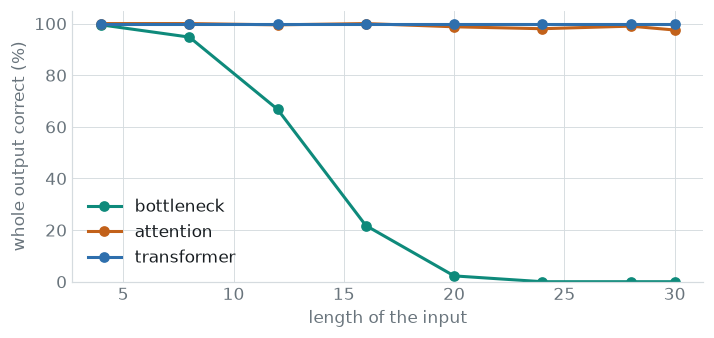

In [6]:
lengths = [4, 8, 12, 16, 20, 24, 28, 30]; plt.figure(figsize=(7.4, 3.2))
for name, m in models.items():
    acc = []
    for L in lengths:
        src, tgt = batch(400, L=L, g=torch.Generator().manual_seed(L)); y = greedy(m, src, L + 1); acc.append((y[:, 1:L + 2] == tgt[:, 1:L + 2]).all(1).float().mean().item() * 100)
    plt.plot(lengths, acc, marker="o", label=name); print(f"{name:12s}", [f"{a:.0f}%" for a in acc])
plt.xlabel("length of the input"); plt.ylabel("whole output correct (%)"); plt.ylim(0, 105); plt.legend(); plt.show()

## What the attention learned

Each row is one output step, and shows where in the input the decoder looked. Nobody told the model
that reversal means reading backwards.

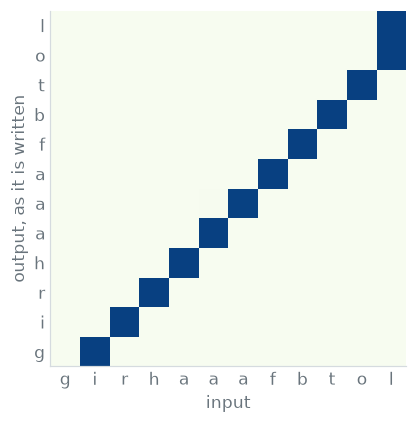

In [7]:
src, tgt = batch(1, L=12, g=torch.Generator().manual_seed(3))
with torch.no_grad(): _, w = models["attention"](src, tgt[:, :-1], want_weights=True)
sym = "abcdefghijklmnopqrst"; plt.figure(figsize=(4.4, 4.2)); plt.imshow(w[0, :12].cpu(), cmap="GnBu", vmin=0, vmax=1)
plt.xticks(range(12), [sym[i] for i in src[0].tolist()]); plt.yticks(range(12), [sym[i] for i in tgt[0, 1:13].tolist()]); plt.xlabel("input"); plt.ylabel("output, as it is written"); plt.grid(False); plt.show()

## Things to try

- Set `TRAIN = True` and change `H`, the width of the single vector. How does the bottleneck model's cliff move?
- Train only on lengths up to 15 (`hi=15` in `batch`) and test on 20. Which models extrapolate?
- Replace reversal with copying. Does the attention pattern become a diagonal the other way?